In [1]:
import numpy as np

file_data = [
    (1.0, "SDS00001.CSV"),
    (1.5, "SDS00002.CSV"),
    (1.8, "SDS00004.CSV"),
    (1.9, "SDS00009.CSV"),
    (2.5, "SDS00010.CSV"),
    (3.0, "SDS00011.CSV"),
    (4.0, "SDS00012.CSV"),
]

for freq, filename in file_data:
    ch1 = []
    try:
        with open(filename, "r", encoding="utf-8-sig") as f:
            lines = f.readlines()

        for line in lines[2:]:
            parts = line.strip().split(",")

            if len(parts) >= 5:
                try:
                    ch1.append(float(parts[4]))
                except ValueError:
                    pass
        if ch1:
            v_min = min(ch1)
            v_max = max(ch1)
            vpp_mv = (v_max - v_min) * 1000

            print(
                f"{freq:.1f} kHz | "
                f"최솟값: {v_min:.6f} V | "
                f"최댓값: {v_max:.6f} V | "
                f"Vpp: {vpp_mv:.2f} mV"
            )
        else:
            print(f"{freq:.1f} kHz | {filename}: 유효한 CH1 데이터가 없습니다.")

    except FileNotFoundError:
        print(f"{freq:.1f} kHz | {filename}: 파일을 찾을 수 없습니다.")
    except Exception as e:
        print(f"{freq:.1f} kHz | {filename} 읽기 오류: {e}")

1.0 kHz | 최솟값: -0.020800 V | 최댓값: 0.022400 V | Vpp: 43.20 mV
1.5 kHz | 최솟값: -0.027200 V | 최댓값: 0.028000 V | Vpp: 55.20 mV
1.8 kHz | 최솟값: -0.024800 V | 최댓값: 0.030400 V | Vpp: 55.20 mV
1.9 kHz | 최솟값: -0.034400 V | 최댓값: 0.025600 V | Vpp: 60.00 mV
2.5 kHz | 최솟값: -0.026400 V | 최댓값: 0.035200 V | Vpp: 61.60 mV
3.0 kHz | 최솟값: -0.028000 V | 최댓값: 0.037600 V | Vpp: 65.60 mV
4.0 kHz | 최솟값: -0.032800 V | 최댓값: 0.040000 V | Vpp: 72.80 mV


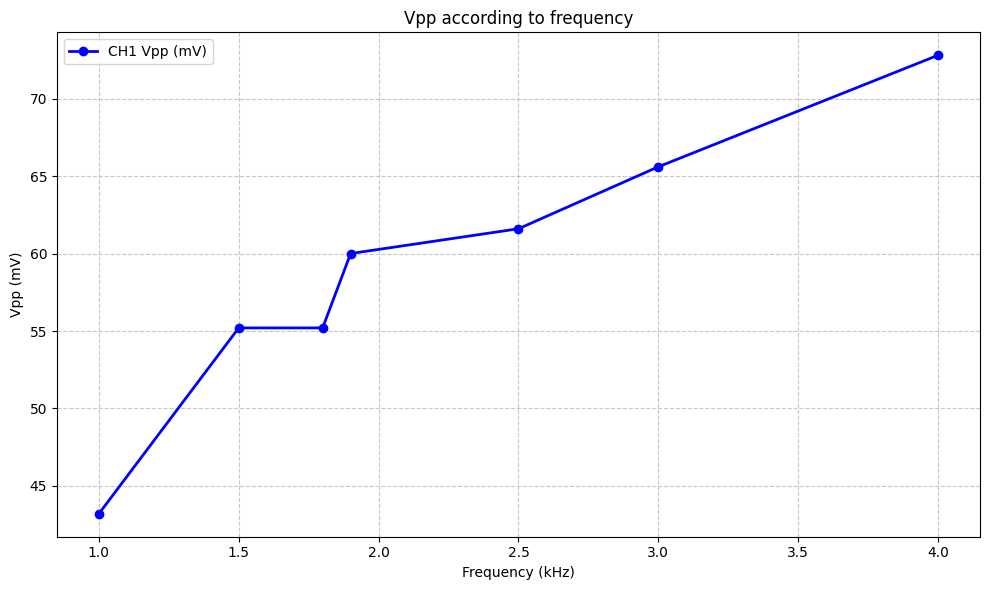

In [10]:
import numpy as np
import matplotlib.pyplot as plt
file_data = [(1.0, 'SDS00001.CSV'),(1.5, 'SDS00002.CSV'), (1.8, 'SDS00004.CSV'), (1.9, 'SDS00009.CSV'), (2.5, 'SDS00010.CSV'), (3.0, 'SDS00011.CSV'), (4.0, 'SDS00012.CSV')]
frequencies = []
ch1_vpp = []
for freq, filename in file_data:
    try:
        ch1 = []
        with open(filename, 'r') as f:
            lines = f.readlines()
            for line in lines[2:]:
                parts = line.strip().split(',')
                if len(parts) >= 5:
                    try:
                        ch1.append(float(parts[4]))
                    except ValueError:
                        pasa
        frequencies.append(freq)
        ch1_vpp.append(np.ptp(ch1) * 1000 if ch1 else 0)
    except Exception as e:
        print(f"{filename} 읽기 오류: {e}")
plt.figure(figsize=(10, 6))
plt.plot(frequencies, ch1_vpp, marker='o', label='CH1 Vpp (mV)', linewidth=2, color='blue')
plt.title('Vpp according to frequency')
plt.xlabel('Frequency (kHz)')
plt.ylabel('Vpp (mV)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

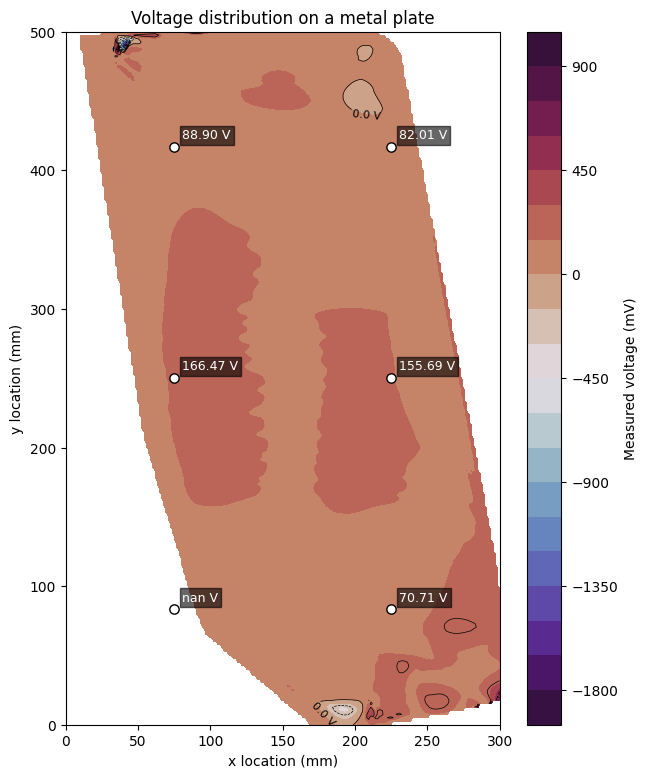

 x_mm       y_mm  voltage_mV
   75  83.333333         NaN
  225  83.333333   70.713095
   75 250.000000  166.473350
  225 250.000000  155.688600
   75 416.666667   88.903439
  225 416.666667   82.009360


In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import griddata

df = pd.read_csv("eddy_scan_data (5).csv")

grid_x, grid_y = np.mgrid[0:300:200j, 0:500:200j]
grid_z = griddata(
    (df["x_mm(가로300 방향, 0=왼쪽 모서리)"], df["y_mm(세로500 방향, 0=위쪽 모서리)"]),
    df["amplitude_Vpp_mV"],
    (grid_x, grid_y),
    method="cubic",
)

center_x = np.array([75, 225])
center_y = np.array([500 / 6, 250, 500 * 5 / 6])
center_xx, center_yy = np.meshgrid(center_x, center_y)

center_voltage = griddata(
    (df["x_mm(가로300 방향, 0=왼쪽 모서리)"], df["y_mm(세로500 방향, 0=위쪽 모서리)"]),
    df["amplitude_Vpp_mV"],
    (center_xx, center_yy),
    method="cubic",
)

plt.figure(figsize=(7, 9))
contour = plt.contourf(
    grid_x, grid_y, grid_z, levels=20, cmap="twilight_shifted"
)
lines = plt.contour(
    grid_x, grid_y, grid_z, levels=12, colors="black", linewidths=0.5
)
plt.clabel(lines, inline=True, fontsize=8, fmt="%.1f V")
plt.colorbar(contour, label="Measured voltage (mV)")

plt.scatter(center_xx, center_yy, color="white", edgecolor="black", s=45, zorder=3)

for x, y, voltage in zip(
    center_xx.ravel(), center_yy.ravel(), center_voltage.ravel()
):
    plt.annotate(
        f"{voltage:.2f} V",
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
        color="white",
        bbox=dict(facecolor="black", alpha=0.6, pad=2),
    )

plt.xlabel("x location (mm)")
plt.ylabel("y location (mm)")
plt.title("Voltage distribution on a metal plate")
plt.xlim(0, 300)
plt.ylim(0, 500)
plt.show()
result = pd.DataFrame({
    "x_mm": center_xx.ravel(),
    "y_mm": center_yy.ravel(),
    "voltage_mV": center_voltage.ravel(),
})
print(result.to_string(index=False))

 그룹   x_mm   y_mm  amplitude_mV
  1  75.00 416.67         61.70
  2 225.00 416.67         37.75
  3  75.00 250.00         93.75
  4 225.00 250.00        101.63
  5  75.00  83.33         77.95
  6 225.00  83.33        220.38


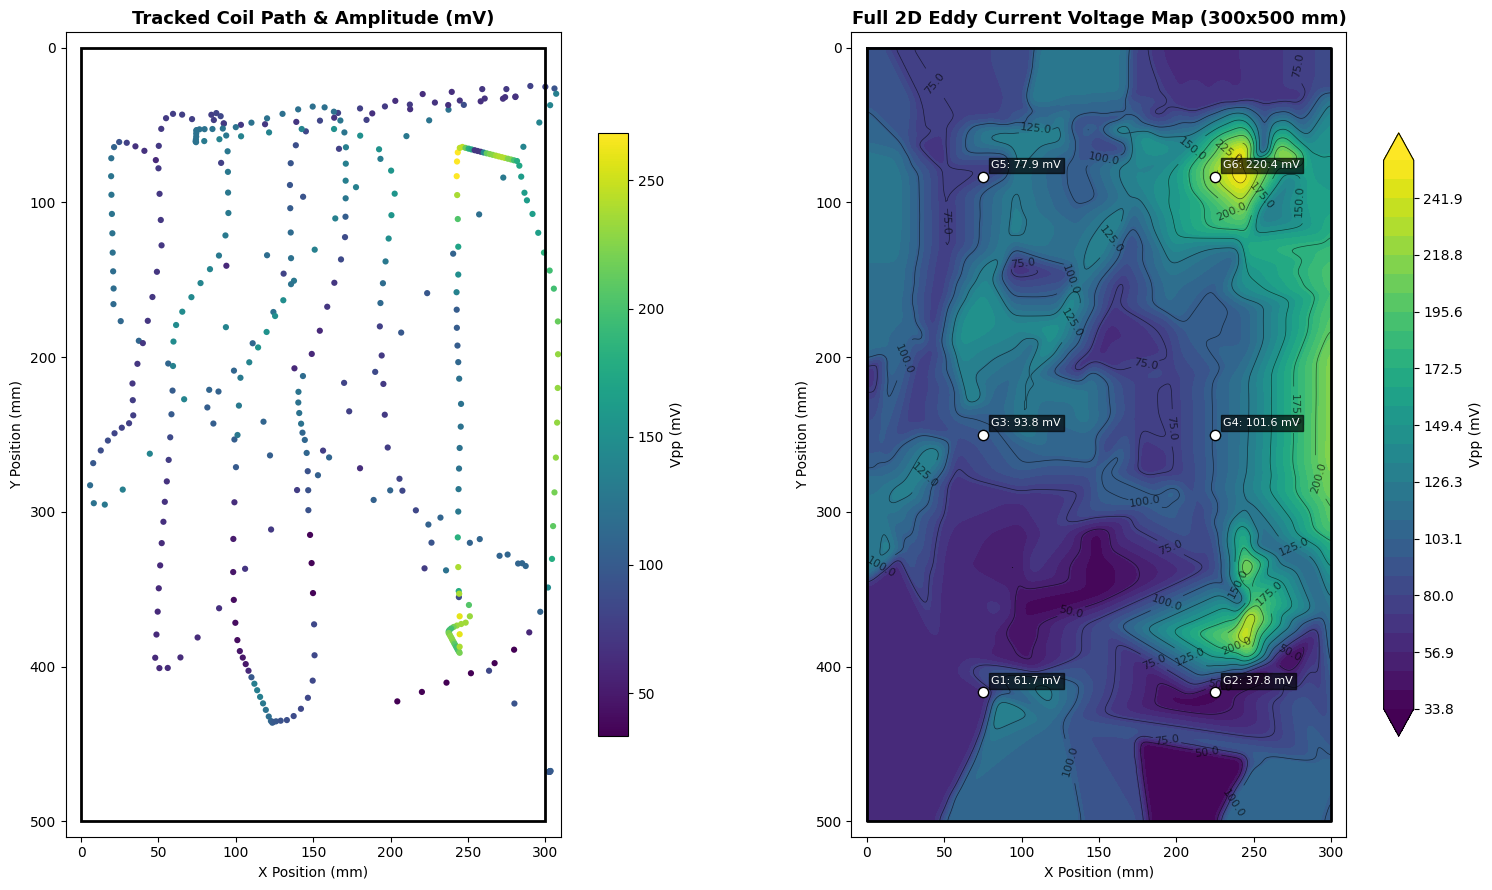

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
df = pd.read_csv('eddy_scan_data (4).csv')

x_col = [c for c in df.columns if 'x_mm' in c][0]
y_col = [c for c in df.columns if 'y_mm' in c][0]
v_col = [c for c in df.columns if 'amplitude' in c][0]

x = df[x_col].to_numpy(dtype=float)
y = df[y_col].to_numpy(dtype=float)
v = df[v_col].to_numpy(dtype=float)
valid_mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(v)
points = np.column_stack((x[valid_mask], y[valid_mask]))
values = v[valid_mask]

grid_x, grid_y = np.mgrid[0:300:301j, 0:500:501j]
grid_z_linear = griddata(points, values, (grid_x, grid_y), method='linear')
grid_z_nearest = griddata(points, values, (grid_x, grid_y), method='nearest')

nan_mask = np.isnan(grid_z_linear)
grid_z = grid_z_linear.copy()
grid_z[nan_mask] = grid_z_nearest[nan_mask]
grid_z_smooth = gaussian_filter(grid_z, sigma=3.0)
center_x = np.array([75, 225, 75, 225, 75, 225], dtype=float)
center_y = np.array([
    500 * 5 / 6, 500 * 5 / 6,  # 위쪽 행
    250, 250,                  # 가운데 행
    500 / 6, 500 / 6           # 아래쪽 행
], dtype=float)
center_values = griddata(
    points,
    values,
    (center_x, center_y),
    method='linear'
)
missing = ~np.isfinite(center_values)
if missing.any():
    center_values[missing] = griddata(
        points, values,
        (center_x[missing], center_y[missing]),
        method='nearest'
    )

result = pd.DataFrame({
    '그룹': np.arange(1, 7),
    'x_mm': center_x,
    'y_mm': center_y,
    'amplitude_mV': center_values,
})
print(result.to_string(index=False, float_format=lambda value: f'{value:.2f}'))

fig, axs = plt.subplots(1, 2, figsize=(16, 9))

sc1 = axs[0].scatter(
    x[valid_mask], y[valid_mask],
    c=v[valid_mask], cmap='viridis', s=20, edgecolors='none'
)
axs[0].add_patch(plt.Rectangle((0, 0), 300, 500, fill=False, ec='k', lw=2))
axs[0].set_xlim(-10, 310)
axs[0].set_ylim(-10, 510)
axs[0].invert_yaxis()
axs[0].set_aspect('equal')
axs[0].set_title('Tracked Coil Path & Amplitude (mV)', fontsize=13, fontweight='bold')
axs[0].set_xlabel('X Position (mm)')
axs[0].set_ylabel('Y Position (mm)')
plt.colorbar(sc1, ax=axs[0], shrink=0.75).set_label('Vpp (mV)')

levels = np.linspace(np.nanmin(grid_z_smooth), np.nanmax(grid_z_smooth), 30)
cf = axs[1].contourf(
    grid_x, grid_y, grid_z_smooth,
    levels=levels, cmap='viridis', extend='both'
)
lines = axs[1].contour(
    grid_x, grid_y, grid_z_smooth,
    levels=10, colors='k', linewidths=0.5, alpha=0.6
)
axs[1].clabel(lines, inline=True, fontsize=8, fmt='%.1f')

axs[1].plot([0, 300, 300, 0, 0], [0, 0, 500, 500, 0], 'k-', lw=2)

axs[1].scatter(
    center_x, center_y, color='white',
    edgecolor='black', s=55, zorder=5
)
for i, (cx, cy, value) in enumerate(zip(center_x, center_y, center_values), start=1):
    axs[1].annotate(
        f'G{i}: {value:.1f} mV',
        (cx, cy),
        xytext=(6, 6),
        textcoords='offset points',
        fontsize=8,
        color='white',
        bbox=dict(facecolor='black', alpha=0.65, pad=2),
        zorder=6
    )

axs[1].set_xlim(-10, 310)
axs[1].set_ylim(-10, 510)
axs[1].invert_yaxis()
axs[1].set_aspect('equal')
axs[1].set_title('Full 2D Eddy Current Voltage Map (300x500 mm)', fontsize=13, fontweight='bold')
axs[1].set_xlabel('X Position (mm)')
axs[1].set_ylabel('Y Position (mm)')
plt.colorbar(cf, ax=axs[1], shrink=0.75).set_label('Vpp (mV)')

plt.tight_layout()
plt.show()